In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import random
from torch.utils.data import Dataset
from collections import defaultdict
from tqdm import tqdm

# 1. Config

In [2]:
config = {
    "data_train_valid_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m/train_valid_sequences.csv",
    "data_test_path": "/kaggle/input/datasets/nhatanhadr/xes3g5m/test_question_window_sequences.csv",
    "num_concepts": 865,
    "size_m": 50,
    "dim_s": 100,
    "hidden_dim": 200,
    "dropout": 0.2,
    "lr": 1e-3,
    "batch_size": 128,
    "num_epochs": 100,
    "patience": 10,
}

# 2. Data Loading

In [3]:
df_train_valid = pd.read_csv(config["data_train_valid_path"])
df_test = pd.read_csv(config["data_test_path"])

print(f"Train: {len(df_train_valid)}")
print(f"Test: {len(df_test)}")

Train: 33397
Test: 697697


# 3. Dataset and DataLoader

In [4]:
def parse_seq(s):
    return list(map(int, s.strip().split(',')))

class DKVMNDataset(Dataset):
    def __init__(self, df, fold=None, is_train=True):
        if fold is not None:
            if is_train:
                df = df[df['fold'] != fold]
            else:
                df = df[df['fold'] == fold]
        self.concepts = [parse_seq(x) for x in df['concepts']]
        self.responses = [parse_seq(x) for x in df['responses']]
        self.selectmasks = [parse_seq(x) for x in df['selectmasks']]
        self.is_repeat = [parse_seq(x) for x in df['is_repeat']]

        # Only in test
        self.qidxs = (
            [parse_seq(x) for x in df['qidxs']]
            if 'qidxs' in df.columns else [None]*len(df)
        )

        self.rest = (
            [parse_seq(x) for x in df['rest']]
            if 'rest' in df.columns else [None]*len(df)
        )

        self.len = len(df)

    def __len__(self):
        return self.len

    def __getitem__(self, i):
        c = torch.tensor(self.concepts[i], dtype=torch.long).clamp(min=0)
        r = torch.tensor(self.responses[i], dtype=torch.long).clamp(min=0)
        m = torch.tensor(self.selectmasks[i], dtype=torch.long)

        item = {
            "concepts": c,
            "responses": r,
            "selectmasks": m
        }

        if self.qidxs[i] is not None:
            item["qidxs"] = torch.tensor(self.qidxs[i], dtype=torch.long)

        if self.rest[i] is not None:
            item["rest"] = torch.tensor(self.rest[i], dtype=torch.long)

        return item

# 4. Model Definition

In [5]:
import torch
import torch.nn as nn
from torch.nn.init import kaiming_normal_

class DKVMN(nn.Module):
    def __init__(self, num_concepts, dim_s, size_m, dropout=0.2):
        super().__init__()
        self.num_concepts = num_concepts
        self.dim_s = dim_s
        self.size_m = size_m

        self.k_emb_layer = nn.Embedding(num_concepts, dim_s)
        self.Mk = nn.Parameter(torch.Tensor(size_m, dim_s))
        self.Mv0 = nn.Parameter(torch.Tensor(size_m, dim_s))

        kaiming_normal_(self.Mk)
        kaiming_normal_(self.Mv0)

        self.v_emb_layer = nn.Embedding(num_concepts*2, dim_s)

        self.f_layer = nn.Linear(dim_s*2, dim_s)
        self.dropout_layer = nn.Dropout(dropout)
        self.p_layer = nn.Linear(dim_s, 1)

        self.a_layer = nn.Linear(dim_s, dim_s)
        self.e_layer = nn.Linear(dim_s, dim_s)

    def forward(self, c, r):
        B, L = c.shape

        x = c + self.num_concepts * r
        k = self.k_emb_layer(c) # (B, L, dim_s)
        v = self.v_emb_layer(x) # (B, L, dim_s)

        Mvt = self.Mv0.unsqueeze(0).repeat(B, 1, 1) # (B, size_m, dim_s)
        Mv = [Mvt]
        w = torch.softmax(torch.matmul(k, self.Mk.T), dim=-1) # (B, L, size_m)

        # Write process
        e = torch.sigmoid(self.e_layer(v)) # (B, L, dim_s)
        a = torch.tanh(self.a_layer(v)) # (B, L, dim_s)

        for et, at, wt in zip(
            e.permute(1, 0, 2), a.permute(1, 0, 2), w.permute(1, 0 , 2)
        ):
            Mvt = Mvt * (1 - (wt.unsqueeze(-1) * et.unsqueeze(1))) + (wt.unsqueeze(-1) * at.unsqueeze(1))
            Mv.append(Mvt)

        Mv = torch.stack(Mv, dim=1) # (B, L+1, size_m, dim_s)

        # Read process
        f = torch.tanh(
            self.f_layer(
                torch.cat(
                    [
                        (w.unsqueeze(-1) * Mv[:, :-1]).sum(-2),
                        k
                    ],
                    dim=-1
                )
            )
        )

        p = self.p_layer(self.dropout_layer(f)) # (B, L, 1)
        logits = p.squeeze(-1) # (B, L)

        return logits

# 5. Compute Metric

In [6]:
import numpy as np
from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    mean_squared_error,
    brier_score_loss,
    average_precision_score,
    f1_score,
)


def expected_calibration_error(y_true, y_prob, n_bins=10):
    """ECE với các bin có độ rộng bằng nhau trên [0, 1]."""
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    # digitize trả về 1..n_bins+1; đưa về chỉ số 0..n_bins-1
    bin_ids = np.clip(np.digitize(y_prob, bins[1:-1], right=True), 0, n_bins - 1)

    ece = 0.0
    n = len(y_true)
    for b in range(n_bins):
        mask = bin_ids == b
        if not mask.any():
            continue
        acc_bin = y_true[mask].mean()      # tần suất "đúng" thực tế trong bin
        conf_bin = y_prob[mask].mean()     # xác suất dự đoán trung bình trong bin
        ece += (mask.sum() / n) * abs(acc_bin - conf_bin)
    return float(ece)


def compute_metrics(y_true, y_pred, threshold=0.5, n_bins=10):
    """
    y_true: nhãn thật (1 = trả lời đúng, 0 = trả lời sai)
    y_pred: xác suất dự đoán P(đúng)
    """
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(float)
    y_pred_binary = (y_pred > threshold).astype(int)

    has_both_classes = len(np.unique(y_true)) > 1

    # --- Nhóm giống pyKT ---
    auc = roc_auc_score(y_true, y_pred) if has_both_classes else 0.5
    acc = accuracy_score(y_true, y_pred_binary)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))

    # --- Nhóm hiệu chỉnh xác suất ---
    brier = brier_score_loss(y_true, y_pred)
    ece = expected_calibration_error(y_true, y_pred, n_bins=n_bins)

    # --- Nhóm cho lớp "sai" (lớp 0, lớp thiểu số ~20%) ---
    # Với lớp "sai" làm lớp dương: nhãn = 1 - y_true, điểm = 1 - P(đúng)
    y_wrong = 1 - y_true
    p_wrong = 1.0 - y_pred
    wrong_pred_binary = 1 - y_pred_binary

    auprc_wrong = (
        average_precision_score(y_wrong, p_wrong) if has_both_classes else float(y_wrong.mean())
    )
    f1_wrong = f1_score(y_wrong, wrong_pred_binary, zero_division=0)

    return {
        "auc": auc,
        "acc": acc,
        "rmse": rmse,
        "brier": brier,
        "ece": ece,
        "auprc_wrong": auprc_wrong,
        "f1_wrong": f1_wrong,
    }

# 6. Evaluate

In [7]:
def dkvmn_evaluate(model, loader, device, question_level=True):
    model.eval()

    if question_level:
            q_preds = defaultdict(list)
            q_labels = defaultdict(list)
    else:
        all_preds = []
        all_labels = []

    loss_sum, n_valid = 0.0, 0
    criterion = nn.BCEWithLogitsLoss(reduction="sum")

    with torch.no_grad():
        for batch in tqdm(loader, desc="Evaluating", leave=False):
            concepts = batch["concepts"].to(device)
            responses = batch["responses"].to(device)
            selectmasks = batch["selectmasks"].to(device)

            if question_level and "qidxs" not in batch:
                raise ValueError("Dataset doesn't have 'qidxs' so it can not evaluate at question level.")

            logits = model(concepts, responses) # (B, L)
            preds = torch.sigmoid(logits)

            mask = selectmasks.clone()
            mask[:, 0] = -1
            valid = mask == 1

            loss_sum += criterion(logits[valid], responses[valid].float()).item()
            n_valid += valid.sum().item()

            if question_level:
                qidxs = batch["qidxs"]
                rest = batch["rest"]
                preds_cpu = preds.cpu()
                targets_cpu = responses.cpu()
                valid_cpu = valid.cpu()
                qidxs_cpu = qidxs.cpu()
                rest_cpu = rest.cpu()

                B, L = preds.shape
                for i in range(B):
                    for t in range(L):
                        if valid_cpu[i, t]:
                            qid = qidxs_cpu[i, t].item()
                            q_preds[qid].append((preds_cpu[i, t].item(), rest_cpu[i, t].item()))
                            q_labels[qid].append(targets_cpu[i, t].item())

            else:
                all_preds.extend(preds[valid].cpu().numpy().tolist())
                all_labels.extend(responses[valid].cpu().numpy().tolist())
        if question_level:
            final_preds, final_trues = [], []
            
            # Check qidxs is valid by rest
            for qid, values in q_preds.items():
                rests = sorted(rest for pred, rest in values)

                if not rests == list(range(len(values))):
                    print(qid, "Not valid")

                pred_list = [p for p, _ in values]
                final_preds.append(float(np.mean(pred_list)))
                final_trues.append(int(np.mean(q_labels[qid]) >= 0.5))

            metrics = compute_metrics(final_trues, final_preds)
        else:
            metrics = compute_metrics(all_labels, all_preds)
            
    metrics["loss"] = loss_sum / max(n_valid, 1)
    
    return metrics

# 7. DKVMN Train Loop

In [8]:
def dkvmn_train_epoch(model, train_loader, valid_loader, optimizer, device, num_epochs=100, patience=5):

    train_loss_history = []
    valid_loss_history = []
    valid_auc_history = []

    best_auc = 0.0
    best_state = None
    no_improve = 0

    for epoch in range(num_epochs):
        # Train
        model.train()
        total_loss = 0.0
        n_valid = 0

        pbar = pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} - Train", leave=False)
        for batch in pbar:
            concepts = batch["concepts"].to(device)
            responses = batch["responses"].to(device)
            selectmasks = batch["selectmasks"].to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = model(concepts, responses)

            criterion = nn.BCEWithLogitsLoss(reduction="sum")

            mask = selectmasks.clone()
            mask[:, 0] = -1
            valid = mask == 1

            n = valid.sum()
            loss = criterion(logits[valid], responses[valid].float())
            (loss / n.clamp(min=1)).backward()
            optimizer.step()

            total_loss += loss.item()
            n_valid += n.item()
            pbar.set_postfix(loss=loss.item())

        avg_train_loss = total_loss / n_valid
        train_loss_history.append(avg_train_loss)

        # Valid
        val_metrics = dkvmn_evaluate(model, valid_loader, device, question_level=False)
        avg_val_loss = val_metrics["loss"]
        valid_loss_history.append(avg_val_loss)
        valid_auc_history.append(val_metrics["auc"])

        print(f"Epoch {epoch+1}: train_loss={avg_train_loss:.4f}, "
                      f"val_loss={avg_val_loss:.4f}, val_auc={val_metrics['auc']:.4f}, "
                      f"val_acc={val_metrics['acc']:.4f}")

        # Early stopping
        if val_metrics["auc"] > best_auc:
            best_auc = val_metrics["auc"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping tại epoch {epoch+1}")
                break

    if best_state is not None:
            model.load_state_dict(best_state)

    history = {
        "train_loss": train_loss_history,
        "valid_loss": valid_loss_history,
        "valid_auc": valid_auc_history,
        "best_auc": best_auc
    }

    return model, history
        


# 8. Training and Evaluating


FOLD 0


Epoch 1: train_loss=0.4687, val_loss=0.4395, val_auc=0.7445, val_acc=0.8093


Epoch 2: train_loss=0.4306, val_loss=0.4233, val_auc=0.7676, val_acc=0.8171


Epoch 3: train_loss=0.4192, val_loss=0.4149, val_auc=0.7782, val_acc=0.8211


Epoch 4: train_loss=0.4125, val_loss=0.4097, val_auc=0.7850, val_acc=0.8229


...

Epoch 96: train_loss=0.3710, val_loss=0.3756, val_auc=0.8243, val_acc=0.8372


Epoch 97: train_loss=0.3710, val_loss=0.3758, val_auc=0.8241, val_acc=0.8369


Epoch 98: train_loss=0.3709, val_loss=0.3754, val_auc=0.8246, val_acc=0.8374


Epoch 99: train_loss=0.3707, val_loss=0.3752, val_auc=0.8248, val_acc=0.8373


Epoch 100: train_loss=0.3706, val_loss=0.3753, val_auc=0.8247, val_acc=0.8374


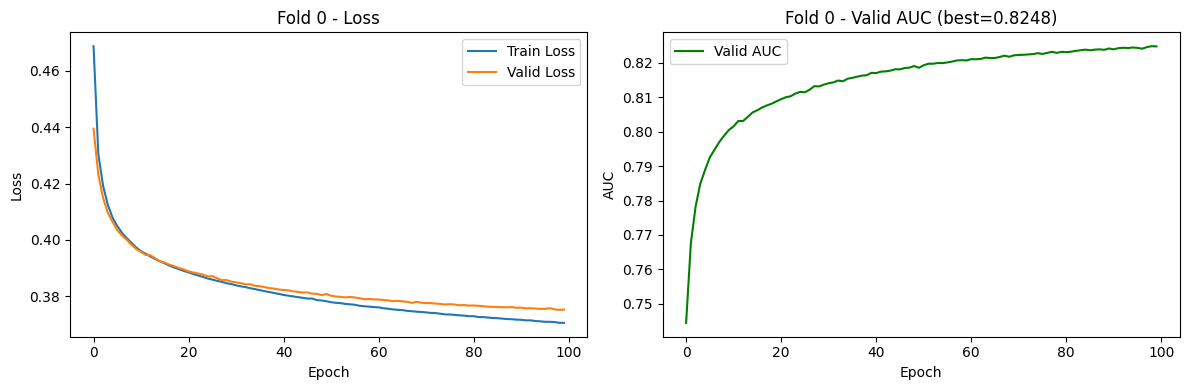

Fold 0 xong. Best valid AUC = 0.8248

FOLD 1


Epoch 1: train_loss=0.4712, val_loss=0.4387, val_auc=0.7432, val_acc=0.8100


Epoch 2: train_loss=0.4322, val_loss=0.4228, val_auc=0.7663, val_acc=0.8174


Epoch 3: train_loss=0.4197, val_loss=0.4138, val_auc=0.7778, val_acc=0.8216


Epoch 4: train_loss=0.4127, val_loss=0.4081, val_auc=0.7851, val_acc=0.8241


...

Epoch 96: train_loss=0.3699, val_loss=0.3728, val_auc=0.8260, val_acc=0.8387


Epoch 97: train_loss=0.3698, val_loss=0.3727, val_auc=0.8259, val_acc=0.8390


Epoch 98: train_loss=0.3696, val_loss=0.3728, val_auc=0.8257, val_acc=0.8387


Epoch 99: train_loss=0.3695, val_loss=0.3729, val_auc=0.8257, val_acc=0.8388


Epoch 100: train_loss=0.3694, val_loss=0.3728, val_auc=0.8258, val_acc=0.8387


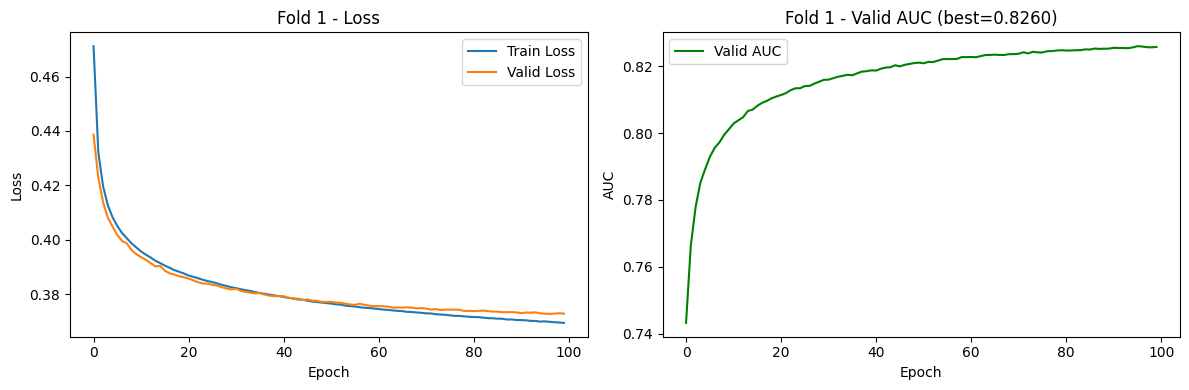

Fold 1 xong. Best valid AUC = 0.8260

FOLD 2


Epoch 1: train_loss=0.4711, val_loss=0.4421, val_auc=0.7469, val_acc=0.8065


Epoch 2: train_loss=0.4324, val_loss=0.4256, val_auc=0.7704, val_acc=0.8148


Epoch 3: train_loss=0.4199, val_loss=0.4170, val_auc=0.7817, val_acc=0.8187


Epoch 4: train_loss=0.4128, val_loss=0.4109, val_auc=0.7891, val_acc=0.8213


...

Epoch 96: train_loss=0.3694, val_loss=0.3747, val_auc=0.8292, val_acc=0.8365


Epoch 97: train_loss=0.3693, val_loss=0.3748, val_auc=0.8293, val_acc=0.8367


Epoch 98: train_loss=0.3691, val_loss=0.3748, val_auc=0.8294, val_acc=0.8365


Epoch 99: train_loss=0.3691, val_loss=0.3745, val_auc=0.8296, val_acc=0.8366


Epoch 100: train_loss=0.3690, val_loss=0.3746, val_auc=0.8295, val_acc=0.8368


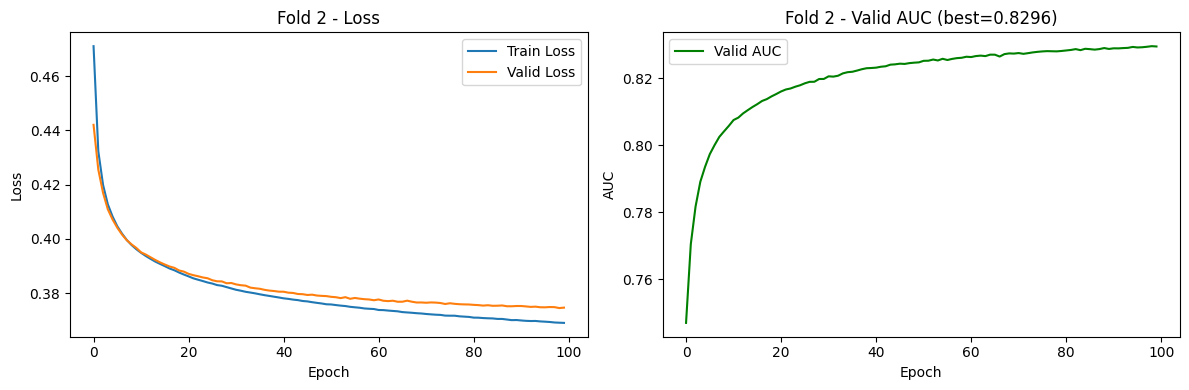

Fold 2 xong. Best valid AUC = 0.8296

FOLD 3


Epoch 1: train_loss=0.4719, val_loss=0.4371, val_auc=0.7453, val_acc=0.8107


Epoch 2: train_loss=0.4325, val_loss=0.4227, val_auc=0.7663, val_acc=0.8173


Epoch 3: train_loss=0.4221, val_loss=0.4153, val_auc=0.7762, val_acc=0.8211


Epoch 4: train_loss=0.4152, val_loss=0.4094, val_auc=0.7837, val_acc=0.8237


...

Epoch 96: train_loss=0.3702, val_loss=0.3719, val_auc=0.8264, val_acc=0.8391


Epoch 97: train_loss=0.3700, val_loss=0.3721, val_auc=0.8263, val_acc=0.8390


Epoch 98: train_loss=0.3699, val_loss=0.3720, val_auc=0.8264, val_acc=0.8394


Epoch 99: train_loss=0.3698, val_loss=0.3720, val_auc=0.8266, val_acc=0.8392


Epoch 100: train_loss=0.3697, val_loss=0.3718, val_auc=0.8264, val_acc=0.8393


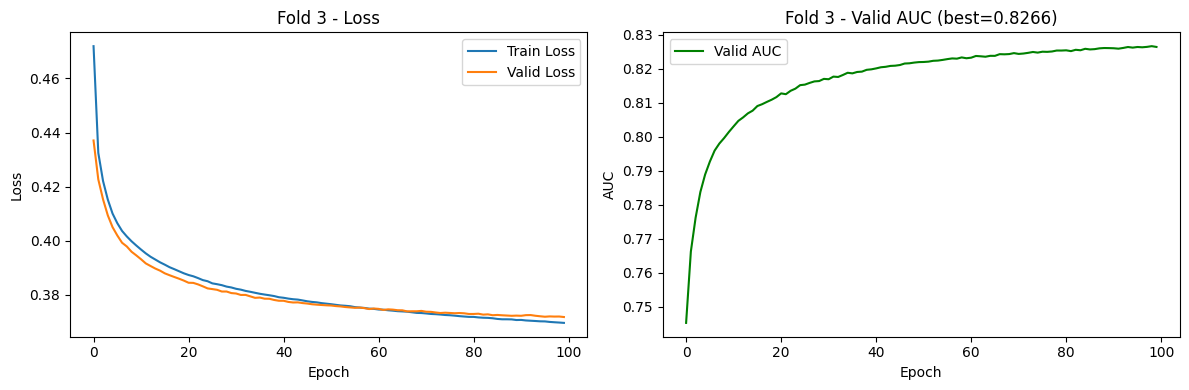

Fold 3 xong. Best valid AUC = 0.8266

FOLD 4


Epoch 1: train_loss=0.4680, val_loss=0.4388, val_auc=0.7470, val_acc=0.8090


Epoch 2: train_loss=0.4285, val_loss=0.4218, val_auc=0.7711, val_acc=0.8167


Epoch 3: train_loss=0.4166, val_loss=0.4132, val_auc=0.7816, val_acc=0.8211


Epoch 4: train_loss=0.4096, val_loss=0.4082, val_auc=0.7878, val_acc=0.8232


...

Epoch 96: train_loss=0.3702, val_loss=0.3757, val_auc=0.8251, val_acc=0.8367


Epoch 97: train_loss=0.3701, val_loss=0.3754, val_auc=0.8256, val_acc=0.8369


Epoch 98: train_loss=0.3701, val_loss=0.3755, val_auc=0.8254, val_acc=0.8369


Epoch 99: train_loss=0.3700, val_loss=0.3754, val_auc=0.8255, val_acc=0.8368


Epoch 100: train_loss=0.3700, val_loss=0.3759, val_auc=0.8255, val_acc=0.8368


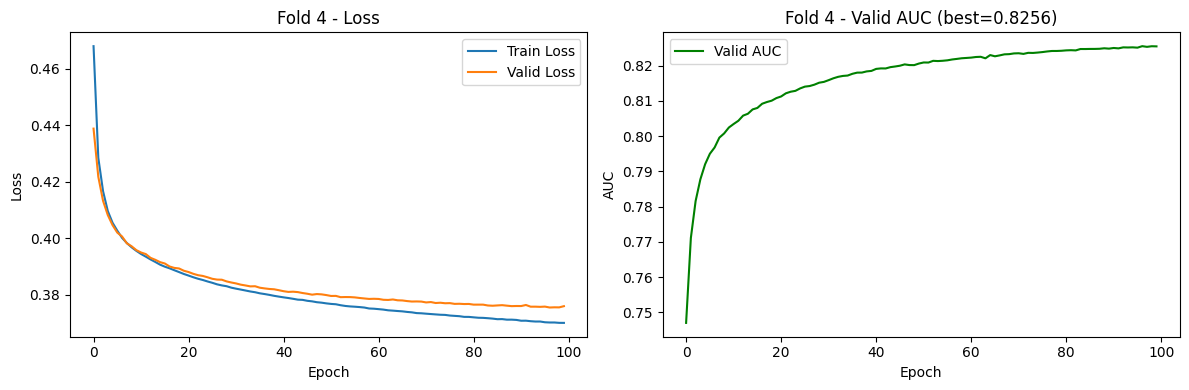

Fold 4 xong. Best valid AUC = 0.8256


In [9]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

trained_models = []
all_histories = []

for i in range(5):
    print(f"\n{'='*50}\nFOLD {i}\n{'='*50}")

    train_dataset = DKVMNDataset(df_train_valid, fold=i, is_train=True)
    valid_dataset = DKVMNDataset(df_train_valid, fold=i, is_train=False)
    train_loader = DataLoader(train_dataset, batch_size=config["batch_size"], shuffle=True)
    valid_loader = DataLoader(valid_dataset, batch_size=config["batch_size"], shuffle=False)

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    model = DKVMN(
        num_concepts=config.get('num_concepts', 865),
        size_m=config.get('size_m', 50),
        dim_s=config.get('dim_s', 100),
        dropout=config.get('dropout', 0.2)
    ).to(device)

    optimizer = torch.optim.Adam(model.parameters(), lr=config.get('lr', 1e-3))

    model, history = dkvmn_train_epoch(
        model, train_loader, valid_loader, optimizer, device,
        num_epochs=config.get('num_epochs', 50),
        patience=config.get('patience', 5)
    )

    trained_models.append(model)
    all_histories.append(history)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history["train_loss"], label="Train Loss")
    axes[0].plot(history["valid_loss"], label="Valid Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title(f"Fold {i} - Loss")
    axes[0].legend()

    axes[1].plot(history["valid_auc"], label="Valid AUC", color="green")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("AUC")
    axes[1].set_title(f"Fold {i} - Valid AUC (best={history['best_auc']:.4f})")
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()

    print(f"Fold {i} xong. Best valid AUC = {history['best_auc']:.4f}")

Fold 0 - Test: auc=0.7759, acc=0.8143, rmse=0.3659, brier=0.1338, ece=0.0089, auprc_wrong=0.4933, f1_wrong=0.3659, loss=0.4295


Fold 1 - Test: auc=0.7763, acc=0.8143, rmse=0.3660, brier=0.1340, ece=0.0141, auprc_wrong=0.4936, f1_wrong=0.3671, loss=0.4314


Fold 2 - Test: auc=0.7761, acc=0.8146, rmse=0.3658, brier=0.1338, ece=0.0103, auprc_wrong=0.4943, f1_wrong=0.3661, loss=0.4301


Fold 3 - Test: auc=0.7764, acc=0.8146, rmse=0.3659, brier=0.1339, ece=0.0146, auprc_wrong=0.4930, f1_wrong=0.3535, loss=0.4310


Fold 4 - Test: auc=0.7754, acc=0.8141, rmse=0.3662, brier=0.1341, ece=0.0100, auprc_wrong=0.4919, f1_wrong=0.3734, loss=0.4311

TỔNG HỢP KẾT QUẢ TEST (5-fold)
AUC       : 0.7760 ± 0.0003
ACC       : 0.8144 ± 0.0002
RMSE      : 0.3660 ± 0.0001
BRIER     : 0.1339 ± 0.0001
ECE       : 0.0116 ± 0.0023
AUPRC_WRONG: 0.4932 ± 0.0008
F1_WRONG  : 0.3652 ± 0.0065


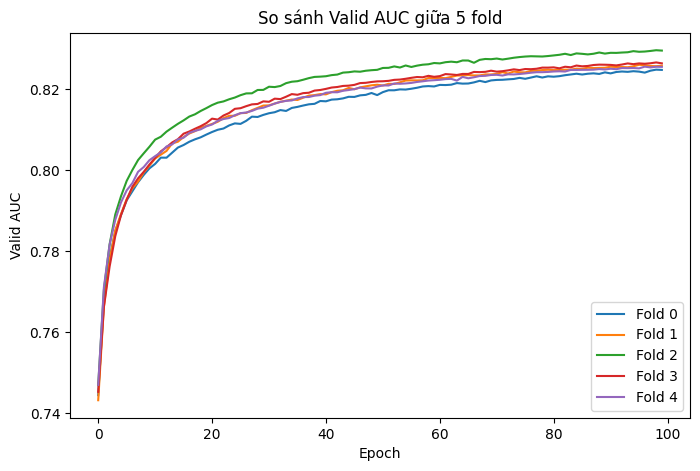

In [10]:
test_dataset = DKVMNDataset(df_test, fold=None, is_train=False)
test_loader = DataLoader(test_dataset, batch_size=config["batch_size"], shuffle=False)

test_results = []

for i, model in enumerate(trained_models):
    metrics = dkvmn_evaluate(model, test_loader, device, question_level=True)
    metrics["fold"] = i
    test_results.append(metrics)
    print(f"Fold {i} - Test: " + ", ".join(f"{k}={v:.4f}" for k, v in metrics.items() if k != "fold"))

metric_names = ["auc", "acc", "rmse", "brier", "ece", "auprc_wrong", "f1_wrong"]

print(f"\n{'='*50}\nTỔNG HỢP KẾT QUẢ TEST (5-fold)\n{'='*50}")
for m in metric_names:
    values = [r[m] for r in test_results]
    print(f"{m.upper():10s}: {np.mean(values):.4f} ± {np.std(values):.4f}")

plt.figure(figsize=(8, 5))
for i, history in enumerate(all_histories):
    plt.plot(history["valid_auc"], label=f"Fold {i}")
plt.xlabel("Epoch")
plt.ylabel("Valid AUC")
plt.title("So sánh Valid AUC giữa 5 fold")
plt.legend()
plt.show()